# Difference-in-Differences на `billboard_impact.csv` (по главе 13 Causality Handbook)

Этот ноутбук повторяет логику статьи:
- показываем, почему наивные оценки смещены,
- считаем классический DiD,
- запускаем наш библиотечный `DifferenceInDifferences`,
- сравниваем результаты с ручным разложением.

Источник: https://matheusfacure.github.io/python-causality-handbook/13-Difference-in-Differences.html


## 1. Импорты и окружение

Что делаем:
- подключаем `advanced_experiments` и базовые библиотеки.

Зачем:
- получить тот же сценарий, но через API нашей библиотеки.


In [1]:
%load_ext autoreload
%autoreload 2

from pathlib import Path
import sys

import numpy as np
import pandas as pd

ROOT = Path.cwd().resolve().parent
if str(ROOT) not in sys.path:
    sys.path.append(str(ROOT))

from cib_advanced_experiments import DifferenceInDifferences, difference_in_differences


## 2. Загружаем данные

Что делаем:
- читаем `billboard_impact.csv` и смотрим структуру.

Зачем:
- убедиться, что колонки соответствуют постановке из статьи: `deposits`, `poa`, `jul`.


In [2]:
raw = pd.read_csv("data/billboard_impact.csv")
raw.head()

,deposits,poa,jul
0,42,1,0
1,0,1,0
2,52,1,0
3,119,1,0
4,21,1,0


In [3]:
print("shape:", raw.shape)
print("columns:", raw.columns.tolist())
raw.describe(include="all")

shape: (4600, 3)
columns: ['deposits', 'poa', 'jul']


,deposits,poa,jul
count,4600.000000,4600.000000,4600.000000
mean,158.288043,0.282609,0.608696
std,102.746131,0.450317,0.488095
min,0.000000,0.000000,0.000000
25%,82.000000,0.000000,0.000000
50%,165.500000,0.000000,1.000000
75%,231.000000,1.000000,1.000000
max,634.000000,1.000000,1.000000


## 3. Быстрая интерпретация признаков

Что делаем:
- считаем средние по комбинациям `poa/jul`.

Зачем:
- это базовый 2x2 каркас для формул before/after и DiD.


In [4]:
cell_means = (
    raw.groupby(["poa", "jul"], as_index=False)["deposits"]
    .mean()
    .sort_values(["poa", "jul"])
)
cell_means

,poa,jul,deposits
0,0,0,171.642308
1,0,1,206.165500
2,1,0,46.016000
3,1,1,87.063750


## 4. Наивная оценка №1: before/after только у treated

Что делаем:
- сравниваем `poa=1` после (`jul=1`) и до (`jul=0`).

Зачем:
- показать смещение, если игнорировать сезонность/общий тренд.


In [5]:
treated_post = raw.loc[(raw["poa"] == 1) & (raw["jul"] == 1), "deposits"].mean()
treated_pre = raw.loc[(raw["poa"] == 1) & (raw["jul"] == 0), "deposits"].mean()
naive_before_after = treated_post - treated_pre

print(f"treated pre mean: {treated_pre:.4f}")
print(f"treated post mean: {treated_post:.4f}")
print(f"naive before/after (treated only): {naive_before_after:.4f}")

treated pre mean: 46.0160
treated post mean: 87.0637
naive before/after (treated only): 41.0478


## 5. Наивная оценка №2: сравнение treated/control только после

Что делаем:
- сравниваем `poa=1` и `poa=0` только в пост-периоде (`jul=1`).

Зачем:
- показать смещение из-за базового различия между группами.


In [6]:
control_post = raw.loc[(raw["poa"] == 0) & (raw["jul"] == 1), "deposits"].mean()
naive_post_only = treated_post - control_post

print(f"control post mean: {control_post:.4f}")
print(f"naive post-only (treated - control): {naive_post_only:.4f}")

control post mean: 206.1655
naive post-only (treated - control): -119.1018


## 6. Ручной DiD по формуле из статьи

Что делаем:
- вычитаем изменение контроля из изменения treated.

Зачем:
- получить «очищенную» оценку treatment-эффекта в 2x2 постановке.


In [7]:
control_pre = raw.loc[(raw["poa"] == 0) & (raw["jul"] == 0), "deposits"].mean()
control_change = control_post - control_pre
treated_change = treated_post - treated_pre
did_manual = treated_change - control_change

print(f"control pre mean: {control_pre:.4f}")
print(f"treated change: {treated_change:.4f}")
print(f"control change: {control_change:.4f}")
print(f"manual DiD: {did_manual:.4f}")

control pre mean: 171.6423
treated change: 41.0478
control change: 34.5232
manual DiD: 6.5246


## 7. Оценка через библиотечный API

Что делаем:
- запускаем `DifferenceInDifferences` на исходных колонках `poa/jul`.

Зачем:
- получить итоговую оценку, CI, p-value и декомпозицию в одном объекте.


In [8]:
did = DifferenceInDifferences(
    data=raw,
    outcome_column="deposits",
    treatment_column="poa",
    post_column="jul",
)
result = did.fit(alpha=0.05)
result

DifferenceInDifferencesResult(estimate=6.524557692307724, std_error=5.7285212913349195, t_statistic=1.1389601889368737, pvalue=0.25477911994453883, ci_lower=-4.706095322367453, ci_upper=17.7552107069829, alpha=0.05, n_obs=4600, group_means=     group  post_period  mean_outcome
0  control            0    171.642308
1  control            1    206.165500
2  treated            0     46.016000
3  treated            1     87.063750, counterfactual_treated_post=80.5391923076923, treated_change=41.04775, control_change=34.52319230769231, naive_before_after=41.04775, naive_post_period_comparison=-119.10175000000001)

In [9]:
print(f"DiD estimate: {result.estimate:.4f}")
print(f"Std. error: {result.std_error:.4f}")
print(f"P-value: {result.pvalue:.6f}")
print(f"95% CI: [{result.ci_lower:.4f}, {result.ci_upper:.4f}]")
print()
print("Breakdown:")
display(did.get_estimators_breakdown())

DiD estimate: 6.5246
Std. error: 5.7285
P-value: 0.254779
95% CI: [-4.7061, 17.7552]

Breakdown:


,estimator,value
0,naive_before_after_treated,41.047750
1,naive_post_period_treated_vs_control,-119.101750
2,did_controlled_difference,6.524558


## 8. Визуализация 2x2

Что делаем:
- строим библиотечный 2x2-график с контрфактом treated-post.

Зачем:
- визуально проверить геометрию DiD-оценки.


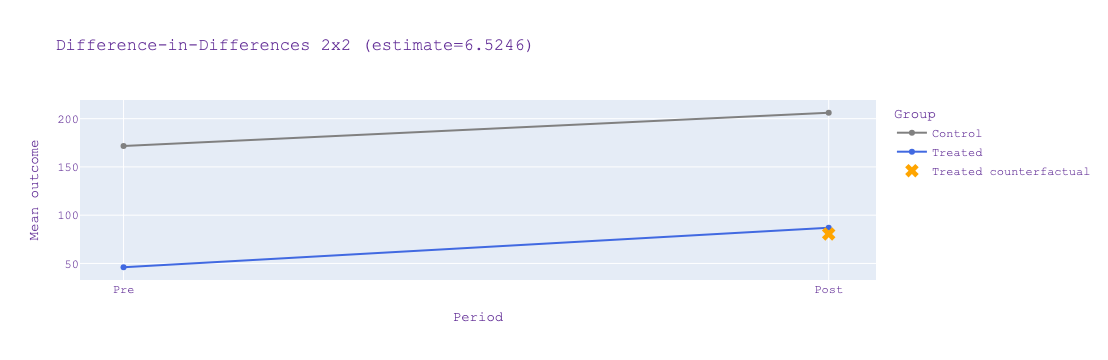

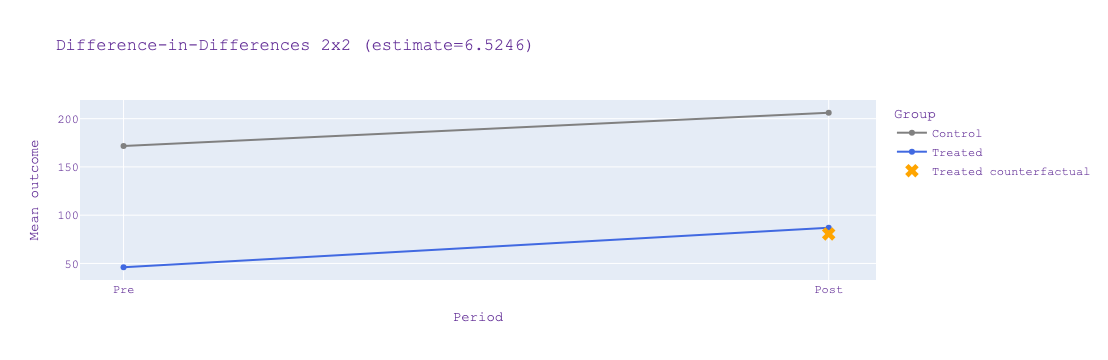

In [10]:
did.plot_2x2()

## 9. Проверка согласованности с ручным расчётом

Что делаем:
- сравниваем ручной и библиотечный DiD.

Зачем:
- убедиться, что API воспроизводит формулу из статьи.


In [11]:
print(f"manual DiD: {did_manual:.10f}")
print(f"library DiD: {result.estimate:.10f}")
print(f"absolute diff: {abs(did_manual - result.estimate):.12f}")

assert np.isclose(did_manual, result.estimate, atol=1e-10)


manual DiD: 6.5245576923
library DiD: 6.5245576923
absolute diff: 0.000000000000


## 10. One-shot API (функциональный стиль)

Что делаем:
- запускаем `difference_in_differences(...)` без создания объекта.

Зачем:
- короткий путь для production-скриптов и быстрых расчётов.


In [12]:
one_shot = difference_in_differences(
    data=raw,
    outcome_column="deposits",
    treatment_column="poa",
    post_column="jul",
)
print(f"one-shot estimate: {one_shot.estimate:.4f}")

one-shot estimate: 6.5246
